# Tier 1: Health Claim Verification with Evidence

Given a health claim and an evidence passage, the model decides whether the evidence supports the claim, refutes it, or does not give enough information. SHAP shows which words drove the decision.

## 1. Setup

In [1]:
import os, sys, json, random, re, ssl, io, urllib.request, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")
os.environ["HF_HUB_DISABLE_XET"] = "1"     # the Xet download backend can stall on some networks
ssl._create_default_https_context = ssl._create_unverified_context

SEED = 42
random.seed(SEED); np.random.seed(SEED)

PROJECT_ROOT = Path.cwd()
RAW_DIR       = PROJECT_ROOT / "datasets" / "raw"
PROCESSED_DIR = PROJECT_ROOT / "datasets" / "processed_tier1"
OUTPUTS_DIR   = PROJECT_ROOT / "outputs"
FIGURES_DIR   = OUTPUTS_DIR / "figures"
MODELS_DIR    = PROJECT_ROOT / "models"

for d in (RAW_DIR, PROCESSED_DIR, OUTPUTS_DIR, FIGURES_DIR, MODELS_DIR):
    d.mkdir(parents=True, exist_ok=True)

# Three-way verification labels
LABELS   = ["SUPPORTED", "REFUTED", "NEI"]
LABEL2ID = {l: i for i, l in enumerate(LABELS)}
ID2LABEL = {i: l for l, i in LABEL2ID.items()}

pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 90)

print(f"Project root : {PROJECT_ROOT}")
print(f"Labels       : {LABEL2ID}")

Project root : C:\Users\nihal\Desktop\Project Phase
Labels       : {'SUPPORTED': 0, 'REFUTED': 1, 'NEI': 2}


## 2. Data acquisition

HealthVer and SciFact, two datasets of health claims paired with evidence.

In [2]:
def _fetch(url, timeout=90):
    req = urllib.request.Request(url, headers={"User-Agent": "Mozilla/5.0"})
    return urllib.request.urlopen(req, timeout=timeout).read()

# ---------------------------------------------------------------- HealthVer
HEALTHVER_DIR = RAW_DIR / "HealthVer"
HEALTHVER_DIR.mkdir(parents=True, exist_ok=True)
HEALTHVER_URL = "https://raw.githubusercontent.com/sarrouti/HealthVer/master/data/healthver_{}.csv"

for split in ["train", "dev", "test"]:
    dest = HEALTHVER_DIR / f"healthver_{split}.csv"
    if dest.exists():
        print(f"cached   {dest.name}")
    else:
        dest.write_bytes(_fetch(HEALTHVER_URL.format(split)))
        print(f"download {dest.name}  ({dest.stat().st_size/1024:.0f} KB)")

# ---------------------------------------------------------------- SciFact
SCIFACT_DIR = RAW_DIR / "SciFact"
SCIFACT_DIR.mkdir(parents=True, exist_ok=True)
SCIFACT_PARQUET = ("https://huggingface.co/datasets/allenai/scifact_entailment/"
                   "resolve/refs%2Fconvert%2Fparquet/default/{}/0000.parquet")

for split in ["train", "validation"]:
    dest = SCIFACT_DIR / f"scifact_{split}.parquet"
    if dest.exists():
        print(f"cached   {dest.name}")
    else:
        dest.write_bytes(_fetch(SCIFACT_PARQUET.format(split)))
        print(f"download {dest.name}  ({dest.stat().st_size/1024:.0f} KB)")

cached   healthver_train.csv
cached   healthver_dev.csv
cached   healthver_test.csv
cached   scifact_train.parquet
cached   scifact_validation.parquet


## 3. Loading and harmonising labels

In [3]:
# ---------------------------------------------------------------- HealthVer
hv_frames = []
for split in ["train", "dev", "test"]:
    d = pd.read_csv(HEALTHVER_DIR / f"healthver_{split}.csv")
    d["orig_split"] = {"dev": "validation"}.get(split, split)
    hv_frames.append(d)
healthver = pd.concat(hv_frames, ignore_index=True)

HV_MAP = {"Supports": "SUPPORTED", "Refutes": "REFUTED", "Neutral": "NEI"}
healthver = healthver.rename(columns={"evidence": "evidence", "claim": "claim"})
healthver["label"] = healthver["label"].map(HV_MAP)
healthver["source"] = "HealthVer"
healthver = healthver[["claim", "evidence", "label", "source", "orig_split"]]

print(f"HealthVer : {len(healthver):,} pairs")
print(healthver["label"].value_counts().to_string())

# ---------------------------------------------------------------- SciFact
sf_frames = []
for split in ["train", "validation"]:
    d = pd.read_parquet(SCIFACT_DIR / f"scifact_{split}.parquet")
    d["orig_split"] = split
    sf_frames.append(d)
scifact = pd.concat(sf_frames, ignore_index=True)

SF_MAP = {"SUPPORT": "SUPPORTED", "CONTRADICT": "REFUTED", "NEI": "NEI"}
scifact["label"] = scifact["verdict"].map(SF_MAP)
scifact["evidence"] = scifact["abstract"].apply(
    lambda a: " ".join(a) if isinstance(a, (list, np.ndarray)) else str(a)
)
scifact["source"] = "SciFact"
scifact = scifact[["claim", "evidence", "label", "source", "orig_split"]]

print(f"\nSciFact   : {len(scifact):,} pairs")
print(scifact["label"].value_counts().to_string())

HealthVer : 14,330 pairs
label
NEI          6117
SUPPORTED    4986
REFUTED      3227



SciFact   : 1,259 pairs
label
SUPPORTED    508
NEI          486
REFUTED      265


In [4]:
# ---------------------------------------------------------------- combine + clean
df = pd.concat([healthver, scifact], ignore_index=True)

n0 = len(df)
df["claim"]    = df["claim"].fillna("").astype(str).str.strip()
df["evidence"] = df["evidence"].fillna("").astype(str).str.strip()

df = df[df["label"].isin(LABELS)]                                     # drop unmapped labels
df = df[df["claim"].str.split().str.len() >= 3]                       # drop stubs
df = df[df["evidence"].str.split().str.len() >= 5]
df = df.drop_duplicates(subset=["claim", "evidence"])                 # exact duplicate pairs
df = df.reset_index(drop=True)

print(f"combined : {n0:,} -> {len(df):,} pairs after cleaning")
print(f"unique claims   : {df['claim'].nunique():,}")
print(f"unique evidence : {df['evidence'].nunique():,}")
print()
print(pd.crosstab(df["source"], df["label"], margins=True).to_string())

combined : 15,589 -> 14,556 pairs after cleaning
unique claims   : 2,956
unique evidence : 1,401

label       NEI  REFUTED  SUPPORTED    All
source                                    
HealthVer  5106     3221       4976  13303
SciFact     482      265        506   1253
All        5588     3486       5482  14556


## 4. Exploratory analysis

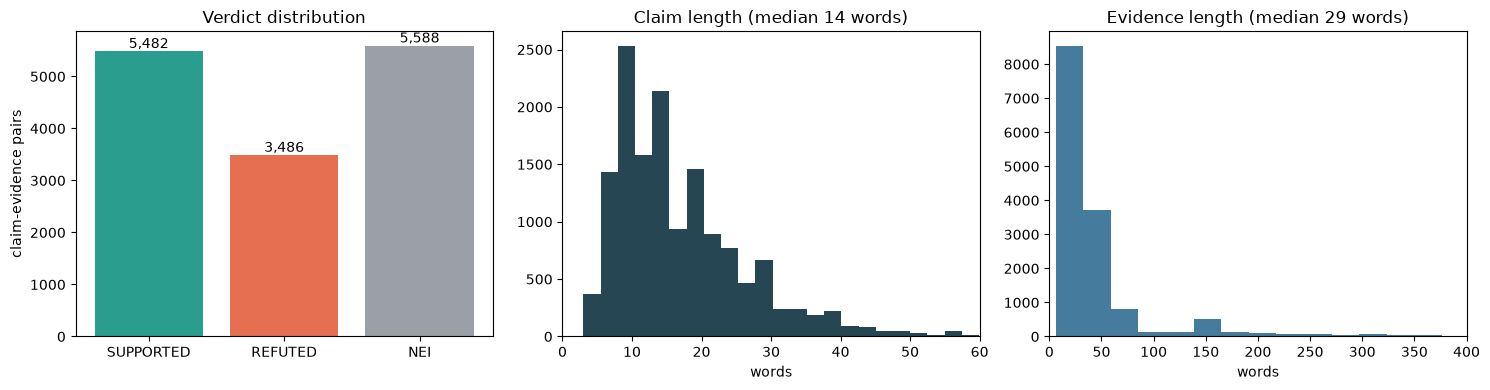

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

# --- label balance
lab = df["label"].value_counts().reindex(LABELS)
axes[0].bar(lab.index, lab.values, color=["#2a9d8f", "#e76f51", "#9aa0a6"])
axes[0].set_title("Verdict distribution")
axes[0].set_ylabel("claim-evidence pairs")
for i, v in enumerate(lab.values):
    axes[0].text(i, v, f"{v:,}", ha="center", va="bottom")

# --- claim length
cw = df["claim"].str.split().str.len()
axes[1].hist(cw, bins=40, color="#264653")
axes[1].set_title(f"Claim length (median {cw.median():.0f} words)")
axes[1].set_xlabel("words"); axes[1].set_xlim(0, 60)

# --- evidence length
ew = df["evidence"].str.split().str.len()
axes[2].hist(ew, bins=40, color="#457b9d")
axes[2].set_title(f"Evidence length (median {ew.median():.0f} words)")
axes[2].set_xlabel("words"); axes[2].set_xlim(0, 400)

plt.tight_layout()
plt.savefig(FIGURES_DIR / "tier1_data_overview.png", dpi=150)
plt.show()

### 4.1 Does the same claim get different verdicts?

If it does, the verdict depends on the evidence and not on how the claim is worded.

In [6]:
per_claim = df.groupby("claim")["label"].nunique()
multi = (per_claim > 1).sum()

print(f"claims appearing with more than one verdict : {multi:,} / {len(per_claim):,} "
      f"({multi/len(per_claim):.1%})")
print(f"average evidence passages per claim        : {df.groupby('claim').size().mean():.1f}")
print()

example = per_claim[per_claim > 1].index[0]
sub = df[df["claim"] == example][["label", "evidence"]].head(3)
print("EXAMPLE — one claim, different evidence, different verdicts")
print("=" * 78)
print(f"CLAIM: {example}\n")
for _, r in sub.iterrows():
    print(f"  [{r['label']}]  {r['evidence'][:190]}...\n")

claims appearing with more than one verdict : 1,048 / 2,956 (35.5%)
average evidence passages per claim        : 4.9

EXAMPLE — one claim, different evidence, different verdicts
CLAIM: 'Social distancing' could help stop coronavirus spread

  [SUPPORTED]  social distancing and have seen slowing the spread of COVID-19....

  [NEI]  The Greek authorities implemented the strong social distancing measures within the first few weeks after the first confirmed case of the virus to curtail the COVID-19 growth rate....

  [REFUTED]  Full lockdown policies in Western Europe countries have no evident impacts on the COVID-19 epidemic....



### 4.2 Can claim text alone predict the verdict?

A bag of words logistic regression on the claim only.

In [7]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split as _tts
from sklearn.metrics import accuracy_score

_claims = df.drop_duplicates(subset=["claim", "label"])
_Xtr, _Xte, _ytr, _yte = _tts(_claims["claim"], _claims["label"],
                              test_size=0.25, random_state=SEED, stratify=_claims["label"])

_vec = TfidfVectorizer(max_features=20000, ngram_range=(1, 2), stop_words="english")
_clf = LogisticRegression(max_iter=2000, class_weight="balanced")
_clf.fit(_vec.fit_transform(_Xtr), _ytr)
_acc = accuracy_score(_yte, _clf.predict(_vec.transform(_Xte)))
_baseline = _yte.value_counts(normalize=True).max()

print(f"claim-text-only accuracy      : {_acc:.3f}")
print(f"majority-class baseline       : {_baseline:.3f}")
print(f"lift over guessing            : {_acc - _baseline:+.3f}")
print()
if _acc - _baseline < 0.15:
    print("=> Claim text alone carries little signal. The style shortcut is gone;")
    print("   the model must read the evidence to do well. This is what we want.")
else:
    print("=> WARNING: claim text alone is still predictive. Investigate before training.")

claim-text-only accuracy      : 0.271
majority-class baseline       : 0.402
lift over guessing            : -0.131

=> Claim text alone carries little signal. The style shortcut is gone;
   the model must read the evidence to do well. This is what we want.


## 5. Train / validation / test split

Split by claim, so no claim appears in two splits.

In [8]:
from sklearn.model_selection import train_test_split

claims = df[["claim"]].drop_duplicates().reset_index(drop=True)
# stratify claims by their dominant verdict so splits stay balanced
claim_lab = df.groupby("claim")["label"].agg(lambda s: s.value_counts().index[0])
claims["strat"] = claims["claim"].map(claim_lab)

tr_c, tmp_c = train_test_split(claims, test_size=0.30, random_state=SEED, stratify=claims["strat"])
va_c, te_c  = train_test_split(tmp_c,  test_size=0.50, random_state=SEED, stratify=tmp_c["strat"])

split_of = {}
for name, part in [("train", tr_c), ("validation", va_c), ("test", te_c)]:
    for c in part["claim"]:
        split_of[c] = name
df["split"] = df["claim"].map(split_of)

train_df = df[df.split == "train"].reset_index(drop=True)
val_df   = df[df.split == "validation"].reset_index(drop=True)
test_df  = df[df.split == "test"].reset_index(drop=True)

# leakage assertion - this must hold
for a, b in [(train_df, val_df), (train_df, test_df), (val_df, test_df)]:
    assert not (set(a["claim"]) & set(b["claim"])), "claim overlap between splits!"
print("leakage check passed: no claim appears in more than one split\n")

summary = pd.DataFrame({
    name: d["label"].value_counts().reindex(LABELS)
    for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]
}).fillna(0).astype(int)
summary.loc["TOTAL"] = summary.sum()
print(summary.to_string())
print()
for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    print(f"{name:<11} {len(d):>6,} pairs   {d['claim'].nunique():>5,} claims")

for name, d in [("train", train_df), ("validation", val_df), ("test", test_df)]:
    d.to_csv(PROCESSED_DIR / f"{name}.csv", index=False)
print(f"\nsaved to {PROCESSED_DIR}")

leakage check passed: no claim appears in more than one split

           train  validation  test
label                             
SUPPORTED   3725         910   847
REFUTED     2412         570   504
NEI         3958         816   814
TOTAL      10095        2296  2165

train       10,095 pairs   2,069 claims
validation   2,296 pairs     443 claims
test         2,165 pairs     444 claims

saved to C:\Users\nihal\Desktop\Project Phase\datasets\processed_tier1


## 6. Model setup

Input `[CLS] claim [SEP] evidence [SEP]`, 256 tokens. PubMedBERT and BERT-base are compared under identical settings and selected on macro F1.

In [9]:
import time
import torch
import torch.nn as nn
from datasets import Dataset
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, precision_recall_fscore_support)
from sklearn.utils.class_weight import compute_class_weight
from transformers import (AutoTokenizer, AutoModelForSequenceClassification,
                          TrainingArguments, Trainer, DataCollatorWithPadding,
                          EarlyStoppingCallback)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
torch.manual_seed(SEED)

PUBMEDBERT = "microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext"
BERTBASE   = "bert-base-uncased"
MAX_LEN    = 256

print(f"Device: {DEVICE}")
if DEVICE == "cuda":
    print(f"GPU   : {torch.cuda.get_device_name(0)} "
          f"({torch.cuda.get_device_properties(0).total_memory/1e9:.1f} GB)")

Device: cuda
GPU   : NVIDIA GeForce RTX 5050 Laptop GPU (8.5 GB)


In [10]:
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=-1)
    # 3-class target, so per-class scores must use average=None with an explicit
    # label list; average="binary" is only valid for two classes.
    p, r, f1, _ = precision_recall_fscore_support(
        labels, preds, labels=[LABEL2ID["REFUTED"]], average=None, zero_division=0)
    return {
        "accuracy": accuracy_score(labels, preds),
        "f1_macro": f1_score(labels, preds, average="macro", zero_division=0),
        "f1_refuted": float(f1[0]),
        "recall_refuted": float(r[0]),
    }


def make_trainer_class(class_weights):
    """Trainer with class-weighted cross-entropy."""
    w = torch.tensor(class_weights, dtype=torch.float32).to(DEVICE)

    class WeightedTrainer(Trainer):
        def compute_loss(self, model, inputs, return_outputs=False, **kwargs):
            labels = inputs.pop("labels")
            out = model(**inputs)
            loss = nn.CrossEntropyLoss(weight=w)(
                out.logits.view(-1, len(LABELS)), labels.view(-1))
            return (loss, out) if return_outputs else loss

    return WeightedTrainer


def train_and_evaluate(base_model, run_name, use_evidence=True,
                       epochs=4, batch_size=16, lr=2e-5, force_retrain=False):
    """Fine-tune one backbone and evaluate it on the held-out test set.

    use_evidence=False trains on the claim alone - used for the ablation in section 8.
    """
    save_dir = MODELS_DIR / run_name
    save_dir.mkdir(parents=True, exist_ok=True)
    has_ckpt = (save_dir / "config.json").exists() and not force_retrain

    tok = AutoTokenizer.from_pretrained(save_dir if has_ckpt else base_model)

    def encode(frame):
        data = {"labels": frame["label"].map(LABEL2ID).astype(int).tolist()}
        if use_evidence:
            data["text"], data["pair"] = frame["claim"].tolist(), frame["evidence"].tolist()
        else:
            data["text"] = frame["claim"].tolist()
        ds = Dataset.from_dict(data)

        def _tok(b):
            if use_evidence:
                return tok(b["text"], b["pair"], truncation="only_second", max_length=MAX_LEN)
            return tok(b["text"], truncation=True, max_length=MAX_LEN)

        drop = [c for c in ("text", "pair") if c in ds.column_names]
        return ds.map(_tok, batched=True, remove_columns=drop)

    ds_tr, ds_va = encode(train_df), encode(val_df)
    seconds = None

    if has_ckpt:
        print(f"[{run_name}] loading cached checkpoint (set force_retrain=True to redo)")
        model = AutoModelForSequenceClassification.from_pretrained(save_dir).to(DEVICE)
    else:
        print(f"[{run_name}] training {base_model}  evidence={use_evidence}")
        model = AutoModelForSequenceClassification.from_pretrained(
            base_model, num_labels=len(LABELS), id2label=ID2LABEL, label2id=LABEL2ID
        ).to(DEVICE)

        cw = compute_class_weight("balanced", classes=np.arange(len(LABELS)),
                                  y=train_df["label"].map(LABEL2ID).values)
        args = TrainingArguments(
            output_dir=str(OUTPUTS_DIR / "trainer_ckpts" / run_name),
            eval_strategy="epoch", save_strategy="epoch", save_total_limit=1,
            learning_rate=lr,
            per_device_train_batch_size=batch_size,
            per_device_eval_batch_size=batch_size * 2,
            num_train_epochs=epochs, warmup_ratio=0.1, weight_decay=0.01,
            load_best_model_at_end=True, metric_for_best_model="f1_macro",
            greater_is_better=True, logging_steps=100, report_to=[], seed=SEED,
            fp16=(DEVICE == "cuda"), disable_tqdm=True,
        )
        trainer = make_trainer_class(cw)(
            model=model, args=args, train_dataset=ds_tr, eval_dataset=ds_va,
            processing_class=tok, data_collator=DataCollatorWithPadding(tok),
            compute_metrics=compute_metrics,
            callbacks=[EarlyStoppingCallback(early_stopping_patience=2)],
        )
        t0 = time.time(); trainer.train(); seconds = time.time() - t0
        model.save_pretrained(save_dir); tok.save_pretrained(save_dir)
        print(f"[{run_name}] trained in {seconds/60:.1f} min")

    probs = predict(model, tok, test_df, use_evidence)
    y_true = test_df["label"].map(LABEL2ID).astype(int).to_numpy()
    y_pred = probs.argmax(-1)

    result = {
        "run": run_name, "backbone": base_model, "evidence": use_evidence,
        "train_minutes": None if seconds is None else round(seconds / 60, 2),
        "accuracy": round(accuracy_score(y_true, y_pred), 4),
        "f1_macro": round(f1_score(y_true, y_pred, average="macro", zero_division=0), 4),
        "f1_refuted": round(float(f1_score(y_true, y_pred, labels=[LABEL2ID["REFUTED"]],
                                           average=None, zero_division=0)[0]), 4),
    }
    print(f"[{run_name}] TEST accuracy={result['accuracy']}  macro-F1={result['f1_macro']}")
    return result, model, tok, probs, y_true


@torch.no_grad()
def predict(model, tok, frame, use_evidence=True, batch_size=32):
    model.eval()
    claims = frame["claim"].tolist()
    evid   = frame["evidence"].tolist() if use_evidence else None
    out = []
    for i in range(0, len(claims), batch_size):
        if use_evidence:
            enc = tok(claims[i:i+batch_size], evid[i:i+batch_size],
                      truncation="only_second", padding=True,
                      max_length=MAX_LEN, return_tensors="pt")
        else:
            enc = tok(claims[i:i+batch_size], truncation=True, padding=True,
                      max_length=MAX_LEN, return_tensors="pt")
        enc = {k: v.to(DEVICE) for k, v in enc.items()}
        out.append(torch.softmax(model(**enc).logits, dim=-1).float().cpu().numpy())
    return np.concatenate(out, axis=0)

print("training helpers defined")

training helpers defined


## 7. Train the main model: PubMedBERT with evidence

In [11]:
results = []

res_pubmed, model_pubmed, tok_pubmed, probs_pubmed, y_true = train_and_evaluate(
    PUBMEDBERT, "tier1_pubmedbert_evidence", use_evidence=True)
results.append(res_pubmed)

Map:   0%|          | 0/10095 [00:00<?, ? examples/s]

Map:  30%|██▉       | 3000/10095 [00:00<00:00, 23872.64 examples/s]

Map:  69%|██████▉   | 7000/10095 [00:00<00:00, 26880.14 examples/s]

Map:  99%|█████████▉| 10000/10095 [00:00<00:00, 21769.81 examples/s]

Map: 100%|██████████| 10095/10095 [00:00<00:00, 21684.02 examples/s]

Map:   0%|          | 0/2296 [00:00<?, ? examples/s]

... (2 outputs left out)

[tier1_pubmedbert_evidence] loading cached checkpoint (set force_retrain=True to redo)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 3840.41it/s]

[tier1_pubmedbert_evidence] TEST accuracy=0.7441  macro-F1=0.7404


In [12]:
y_pred = probs_pubmed.argmax(-1)
print("PubMedBERT + evidence — held-out test set\n")
print(classification_report(y_true, y_pred, target_names=LABELS, digits=3, zero_division=0))

PubMedBERT + evidence — held-out test set

              precision    recall  f1-score   support

   SUPPORTED      0.751     0.707     0.728       847
     REFUTED      0.658     0.766     0.708       504
         NEI      0.803     0.769     0.785       814

    accuracy                          0.744      2165
   macro avg      0.737     0.747     0.740      2165
weighted avg      0.748     0.744     0.745      2165



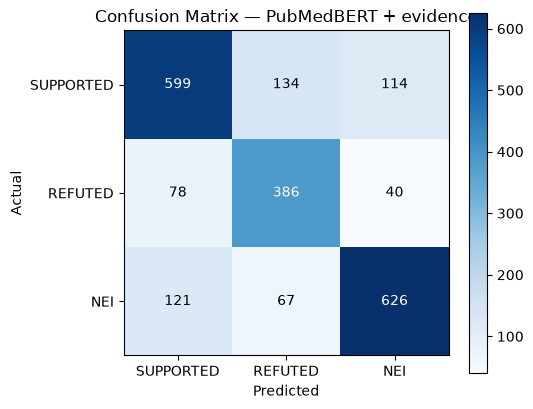

In [13]:
cm = confusion_matrix(y_true, y_pred)
fig, ax = plt.subplots(figsize=(5.5, 4.5))
im = ax.imshow(cm, cmap="Blues")
ax.set_xticks(range(len(LABELS))); ax.set_xticklabels(LABELS)
ax.set_yticks(range(len(LABELS))); ax.set_yticklabels(LABELS)
ax.set_xlabel("Predicted"); ax.set_ylabel("Actual")
ax.set_title("Confusion Matrix — PubMedBERT + evidence")
for i in range(len(LABELS)):
    for j in range(len(LABELS)):
        ax.text(j, i, cm[i, j], ha="center", va="center",
                color="white" if cm[i, j] > cm.max()/2 else "black")
fig.colorbar(im)
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tier1_confusion_matrix.png", dpi=150)
plt.show()

## 8. Does the evidence matter? (ablation)

The same model trained on the same claims with the evidence removed.

In [14]:
res_noevid, *_ = train_and_evaluate(
    PUBMEDBERT, "tier1_pubmedbert_claim_only", use_evidence=False)
results.append(res_noevid)

Map:   0%|          | 0/10095 [00:00<?, ? examples/s]

Map:  79%|███████▉  | 8000/10095 [00:00<00:00, 63291.74 examples/s]

Map: 100%|██████████| 10095/10095 [00:00<00:00, 62447.00 examples/s]

Map:   0%|          | 0/2296 [00:00<?, ? examples/s]

Map: 100%|██████████| 2296/2296 [00:00<00:00, 54412.08 examples/s]

[tier1_pubmedbert_claim_only] loading cached checkpoint (set force_retrain=True to redo)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 3445.34it/s]

[tier1_pubmedbert_claim_only] TEST accuracy=0.5266  macro-F1=0.508


## 9. Does biomedical pretraining help?

In [15]:
res_bert, model_bert, tok_bert, probs_bert, _ = train_and_evaluate(
    BERTBASE, "tier1_bertbase_evidence", use_evidence=True)
results.append(res_bert)

Map:   0%|          | 0/10095 [00:00<?, ? examples/s]

Map:  40%|███▉      | 4000/10095 [00:00<00:00, 26318.40 examples/s]

Map:  79%|███████▉  | 8000/10095 [00:00<00:00, 27143.83 examples/s]

Map: 100%|██████████| 10095/10095 [00:00<00:00, 21680.90 examples/s]

Map:   0%|          | 0/2296 [00:00<?, ? examples/s]

Map: 100%|██████████| 2296/2296 [00:00<00:00, 20564.70 examples/s]

Map: 100%|██████████| 2296/2296 [00:00<00:00, 20074.51 examples/s]

[tier1_bertbase_evidence] loading cached checkpoint (set force_retrain=True to redo)


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 201/201 [00:00<00:00, 3114.64it/s]

[tier1_bertbase_evidence] TEST accuracy=0.7219  macro-F1=0.7121


In [16]:
majority = test_df["label"].value_counts(normalize=True).max()

comparison = pd.DataFrame(results)[
    ["run", "backbone", "evidence", "accuracy", "f1_macro", "f1_refuted", "train_minutes"]]
comparison["backbone"] = comparison["backbone"].str.replace(
    "microsoft/BiomedNLP-PubMedBERT-base-uncased-abstract-fulltext", "PubMedBERT", regex=False)
comparison.to_csv(OUTPUTS_DIR / "tier1_model_comparison.csv", index=False)

print(f"majority-class baseline accuracy: {majority:.3f}\n")
print(comparison.to_string(index=False))

majority-class baseline accuracy: 0.391

                        run          backbone  evidence  accuracy  f1_macro  f1_refuted train_minutes
  tier1_pubmedbert_evidence        PubMedBERT      True    0.7441    0.7404      0.7076          None
tier1_pubmedbert_claim_only        PubMedBERT     False    0.5266    0.5080      0.3918          None
    tier1_bertbase_evidence bert-base-uncased      True    0.7219    0.7121      0.6409          None


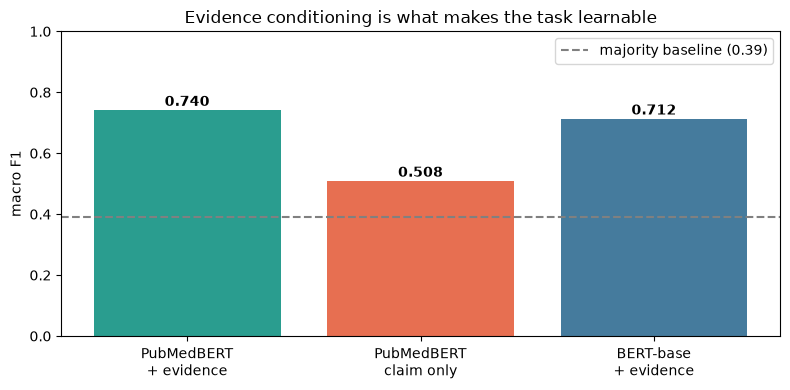

In [17]:
fig, ax = plt.subplots(figsize=(8, 4))
lbls = ["PubMedBERT\n+ evidence", "PubMedBERT\nclaim only", "BERT-base\n+ evidence"]
order = ["tier1_pubmedbert_evidence", "tier1_pubmedbert_claim_only", "tier1_bertbase_evidence"]
vals = [comparison.set_index("run").loc[r, "f1_macro"] for r in order]
bars = ax.bar(lbls, vals, color=["#2a9d8f", "#e76f51", "#457b9d"])
ax.axhline(majority, ls="--", c="grey", label=f"majority baseline ({majority:.2f})")
ax.set_ylabel("macro F1"); ax.set_ylim(0, 1)
ax.set_title("Evidence conditioning is what makes the task learnable")
for b, v in zip(bars, vals):
    ax.text(b.get_x()+b.get_width()/2, v+0.015, f"{v:.3f}", ha="center", fontweight="bold")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tier1_ablation.png", dpi=150)
plt.show()

## 10. Explainability with SHAP

An explicit `Text` masker makes SHAP score whole words instead of subword pieces.

In [18]:
import shap
from transformers import TextClassificationPipeline

def build_explainer(model, tok, max_length=MAX_LEN):
    pipe = TextClassificationPipeline(
        model=model, tokenizer=tok,
        device=0 if DEVICE == "cuda" else -1,
        top_k=None, truncation=True, max_length=max_length,
    )
    # THE FIX: force whole-word masking rather than subword slicing
    return shap.Explainer(pipe, shap.maskers.Text(r"\W+"))


STOPWORDS = set("""
a an the is are was were be been being of to in on at for with and or but not no
this that these those it its as by from has have had do does did will would can
could should may might must if then than so such very just only also more most
we our you your they their he she his her at up out about into over after before
""".split())


def top_shap_words(explainer, text, target_label, k=10):
    """Words pushing the prediction toward `target_label`, strongest first."""
    sv = explainer([text])
    tokens = [str(t).strip() for t in sv[0].data]
    vals = sv[0].values
    scores = vals[:, LABEL2ID[target_label]] if getattr(vals, "ndim", 1) > 1 else vals

    seen, out = set(), []
    for w, s in sorted(zip(tokens, scores), key=lambda x: -x[1]):
        wl = w.lower().strip()
        if not wl or wl in STOPWORDS or len(wl) <= 2 or not re.search(r"[a-z]", wl):
            continue
        if wl in seen:
            continue
        seen.add(wl); out.append((wl, float(s)))
        if len(out) == k:
            break
    return out

explainer_pubmed = build_explainer(model_pubmed, tok_pubmed)
print("SHAP explainer ready (whole-word masker)")

SHAP explainer ready (whole-word masker)


In [19]:
# Explain a REFUTED example - the case that matters most for misinformation
_ex = test_df[test_df["label"] == "REFUTED"].iloc[0]
_text = _ex["claim"] + " " + tok_pubmed.sep_token + " " + _ex["evidence"]

print("CLAIM   :", _ex["claim"][:200])
print("EVIDENCE:", _ex["evidence"][:300], "...")
print("GOLD    :", _ex["label"])
print()

_words = top_shap_words(explainer_pubmed, _text, "REFUTED", k=10)
print("Words pushing the model toward REFUTED:")
for w, s in _words:
    bar = "#" * max(1, int(abs(s) * 300))
    print(f"   {w:<18} {s:+.4f}  {bar}")

print()
print("Sanity check - are these whole words rather than subword fragments?")
print("   ", ", ".join(w for w, _ in _words))

CLAIM   : Colloidal silver can cure COVID-19
EVIDENCE: compounds derived from Allium sativum (garlic) have the potential to decrease the expression of proinflammatory cytokines and to reverse the immunological abnormalities to more acceptable levels. Allium sativum is suggested as a beneficial preventive measure before being infected with SARS-CoV-2 vir ...
GOLD    : REFUTED



[transformers] You seem to be using the pipelines sequentially on GPU. In order to maximize efficiency please use a dataset


Words pushing the model toward REFUTED:
   garlic)            +0.0194  #####
   suggested          +0.0187  #####
   reverse            +0.0186  #####
   decrease           +0.0134  ####
   sativum            +0.0121  ###
   cure               +0.0121  ###
   acceptable         +0.0078  ##
   beneficial         +0.0062  #
   infected           +0.0031  #
   potential          +0.0011  #

Sanity check - are these whole words rather than subword fragments?
    garlic), suggested, reverse, decrease, sativum, cure, acceptable, beneficial, infected, potential


## 11. Is the explanation faithful?

Do SHAP's top words fall inside the sentences SciFact's annotators marked as evidence more often than chance?

In [20]:
# Reload SciFact with rationale annotations, restricted to claims in our TEST split
_sf = pd.concat([pd.read_parquet(SCIFACT_DIR / f"scifact_{s}.parquet")
                 for s in ["train", "validation"]], ignore_index=True)
_test_claims = set(test_df["claim"])
_sf = _sf[_sf["claim"].isin(_test_claims) & _sf["verdict"].isin(["SUPPORT", "CONTRADICT"])]
_sf = _sf[_sf["evidence"].map(len) > 0].reset_index(drop=True)

print(f"SciFact test-split rows carrying gold rationales: {len(_sf)}")

def _words_of(text):
    return {w for w in re.findall(r"[a-z]+", str(text).lower())
            if w not in STOPWORDS and len(w) > 2}

rows = []
for _, r in _sf.head(25).iterrows():        # SHAP over full abstracts is slow; 25 is enough to be indicative
    sents = list(r["abstract"])
    gold_idx = set(int(i) for i in r["evidence"])
    if not gold_idx or len(sents) < 2:
        continue

    rationale_words = _words_of(" ".join(sents[i] for i in gold_idx if i < len(sents)))
    all_words       = _words_of(" ".join(sents))
    if not rationale_words or not all_words:
        continue

    target = "REFUTED" if r["verdict"] == "CONTRADICT" else "SUPPORTED"
    text = r["claim"] + " " + tok_pubmed.sep_token + " " + " ".join(sents)
    shap_words = [w for w, _ in top_shap_words(explainer_pubmed, text, target, k=10)]
    shap_words = [w for w in shap_words if w in all_words]     # ignore claim-only words
    if not shap_words:
        continue

    hit  = sum(w in rationale_words for w in shap_words) / len(shap_words)
    base = len(rationale_words) / len(all_words)               # chance level
    rows.append({"claim": r["claim"][:70], "verdict": r["verdict"],
                 "shap_in_rationale": round(hit, 3),
                 "chance_baseline": round(base, 3),
                 "lift": round(hit - base, 3)})

faith = pd.DataFrame(rows)
faith.to_csv(OUTPUTS_DIR / "tier1_faithfulness.csv", index=False)

print(f"\nevaluated {len(faith)} claims\n")
print(f"SHAP words landing in the human-marked rationale : {faith['shap_in_rationale'].mean():.3f}")
print(f"chance baseline (rationale share of abstract)    : {faith['chance_baseline'].mean():.3f}")
print(f"lift over chance                                 : {faith['lift'].mean():+.3f}")
print()
_better = (faith['lift'] > 0).mean()
print(f"claims where SHAP beat chance: {_better:.1%}")
print()
print(faith.head(10).to_string(index=False))

SciFact test-split rows carrying gold rationales: 131


  0%|          | 0/498 [00:00<?, ?it/s]

 97%|█████████▋| 482/498 [00:00<00:00, 3241.70it/s]

  0%|          | 0/498 [00:00<?, ?it/s]

 97%|█████████▋| 482/498 [00:00<00:00, 3087.36it/s]

  0%|          | 0/498 [00:00<?, ?it/s]

504it [00:00, 4053.54it/s]             

  0%|          | 0/498 [00:00<?, ?it/s]

  0%|          | 0/498 [00:00<?, ?it/s]

 93%|█████████▎| 464/498 [00:00<00:00, 3239.80it/s]


evaluated 25 claims

SHAP words landing in the human-marked rationale : 0.456
chance baseline (rationale share of abstract)    : 0.337
lift over chance                                 : +0.120

claims where SHAP beat chance: 72.0%

                                                                 claim    verdict  shap_in_rationale  chance_baseline   lift
APOE4 expression in iPSC-derived neurons results in decreased tau phos CONTRADICT              0.000            0.398 -0.398
Active caspase-11 participate in regulating phagosome-lysosome fusion.    SUPPORT              0.286            0.208  0.077
            Adult tissue-resident macrophages are seeded before birth.    SUPPORT              0.444            0.310  0.134
            Adult tissue-resident macrophages are seeded before birth.    SUPPORT              0.222            0.167  0.056
            Adult tissue-resident macrophages are seeded before birth.    SUPPORT              0.444            0.310  0.134
            Adult

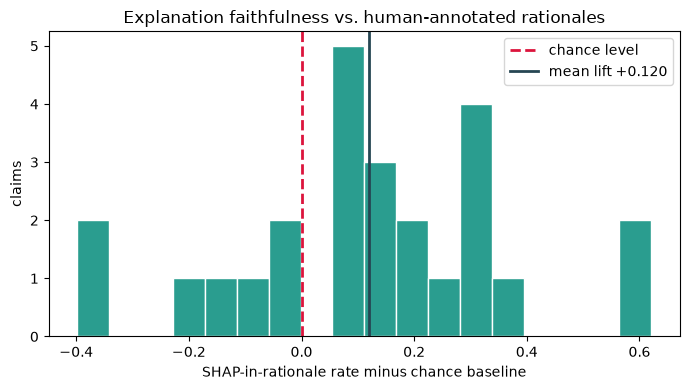

In [21]:
fig, ax = plt.subplots(figsize=(7, 4))
ax.hist(faith["lift"], bins=18, color="#2a9d8f", edgecolor="white")
ax.axvline(0, color="crimson", ls="--", lw=2, label="chance level")
ax.axvline(faith["lift"].mean(), color="#264653", lw=2,
           label=f"mean lift {faith['lift'].mean():+.3f}")
ax.set_xlabel("SHAP-in-rationale rate minus chance baseline")
ax.set_ylabel("claims")
ax.set_title("Explanation faithfulness vs. human-annotated rationales")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tier1_faithfulness.png", dpi=150)
plt.show()

## 12. Evidence retrieval

BM25 and dense PubMedBERT embeddings over peer reviewed passages, combined with reciprocal rank fusion.

In [22]:
# ---------------------------------------------------------------- corpus
_sc = pd.read_parquet(SCIFACT_DIR / "scifact_corpus.parquet")

def _join(a):
    return " ".join(a) if isinstance(a, (list, np.ndarray)) else str(a)

# (a) every evidence passage used in the dataset, stored verbatim. Indexing these
#     exactly is what makes the recall@k measurement in 12.1 meaningful - the gold
#     passage is guaranteed to be findable, so recall reflects the retriever's
#     ranking ability rather than a string-formatting mismatch.
_ev = df[["evidence", "source"]].drop_duplicates(subset=["evidence"])
corpus_rows = [{"text": t, "source": s} for t, s in zip(_ev["evidence"], _ev["source"])]

# (b) the wider SciFact abstract corpus as additional background knowledge, so the
#     retriever has something to say about claims outside the labelled pairs.
corpus_rows += [{"text": f"{r['title']}. {_join(r['abstract'])}", "source": "SciFact-corpus"}
                for _, r in _sc.iterrows()]

corpus = pd.DataFrame(corpus_rows)
corpus["text"] = corpus["text"].str.strip()
corpus = corpus[corpus["text"].str.split().str.len() >= 10]
corpus = corpus.drop_duplicates(subset=["text"]).reset_index(drop=True)

print(f"retrieval corpus: {len(corpus):,} passages")
print(corpus["source"].value_counts().to_string())

retrieval corpus: 6,559 passages
source
SciFact-corpus    5183
HealthVer          709
SciFact            667


In [23]:
# ---------------------------------------------------------------- BM25 (lexical)
from sklearn.feature_extraction.text import CountVectorizer
import scipy.sparse as sp

class BM25:
    """Standard Okapi BM25 over a sparse term-count matrix."""
    def __init__(self, docs, k1=1.5, b=0.75):
        self.k1, self.b = k1, b
        self.vec = CountVectorizer(stop_words="english", min_df=2)
        tf = self.vec.fit_transform(docs).astype(np.float32)     # n_docs x n_terms
        self.tf = tf
        dl = np.asarray(tf.sum(axis=1)).ravel()
        self.dl, self.avgdl = dl, dl.mean()
        n_docs = tf.shape[0]
        n_dt = np.asarray((tf > 0).sum(axis=0)).ravel()          # docs containing term
        self.idf = np.log(1 + (n_docs - n_dt + 0.5) / (n_dt + 0.5)).astype(np.float32)

    def scores(self, query):
        q = self.vec.transform([query])
        idx = q.indices
        if len(idx) == 0:
            return np.zeros(self.tf.shape[0], dtype=np.float32)
        sub = self.tf[:, idx].toarray()                          # n_docs x n_query_terms
        denom = sub + self.k1 * (1 - self.b + self.b * (self.dl / self.avgdl))[:, None]
        return ((sub * (self.k1 + 1) / denom) * self.idf[idx]).sum(axis=1)

bm25 = BM25(corpus["text"].tolist())
print(f"BM25 index built: {bm25.tf.shape[0]:,} docs x {bm25.tf.shape[1]:,} terms")

BM25 index built: 6,559 docs x 20,817 terms


In [24]:
# ---------------------------------------------------------------- dense (semantic)
from transformers import AutoModel

DENSE_CANDIDATES = ["NeuML/pubmedbert-base-embeddings",
                    "sentence-transformers/all-MiniLM-L6-v2"]

dense_ok, dense_tok, dense_model, dense_name = False, None, None, None
for _mid in DENSE_CANDIDATES:
    try:
        dense_tok = AutoTokenizer.from_pretrained(_mid)
        dense_model = AutoModel.from_pretrained(_mid).to(DEVICE).eval()
        dense_name, dense_ok = _mid, True
        break
    except Exception as e:
        print(f"  could not load {_mid}: {type(e).__name__}")

@torch.no_grad()
def embed(texts, batch_size=64, max_length=256):
    outs = []
    for i in range(0, len(texts), batch_size):
        enc = dense_tok(texts[i:i+batch_size], padding=True, truncation=True,
                        max_length=max_length, return_tensors="pt")
        enc = {k: v.to(DEVICE) for k, v in enc.items()}
        h = dense_model(**enc).last_hidden_state
        m = enc["attention_mask"].unsqueeze(-1).float()
        v = (h * m).sum(1) / m.sum(1)                            # mean pooling
        outs.append(torch.nn.functional.normalize(v, dim=-1).float().cpu())
    return torch.cat(outs).numpy()

if dense_ok:
    print(f"dense encoder: {dense_name}")
    t0 = time.time()
    corpus_emb = embed(corpus["text"].tolist())
    print(f"embedded {len(corpus):,} passages in {time.time()-t0:.0f}s  shape={corpus_emb.shape}")
else:
    corpus_emb = None
    print("dense encoder unavailable - retrieval will run BM25-only")

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 3911.39it/s]

dense encoder: NeuML/pubmedbert-base-embeddings


embedded 6,559 passages in 52s  shape=(6559, 768)


In [25]:
# ---------------------------------------------------------------- hybrid retrieval (RRF)
def _rrf_ranks(scores, k_const=60):
    order = np.argsort(-scores)
    rr = np.zeros(len(scores), dtype=np.float32)
    rr[order] = 1.0 / (k_const + np.arange(1, len(scores) + 1))
    return rr

def retrieve_evidence(claim, k=3, mode="hybrid"):
    """Return [(passage, fused_score, source), ...] most relevant to `claim`."""
    lex = bm25.scores(claim)
    if corpus_emb is not None and mode in ("hybrid", "dense"):
        q = embed([claim])
        den = (corpus_emb @ q[0])
    else:
        den = None

    if mode == "bm25" or den is None:
        fused = lex
    elif mode == "dense":
        fused = den
    else:
        fused = _rrf_ranks(lex) + _rrf_ranks(den)

    top = np.argsort(-fused)[:k]
    return [(corpus["text"].iloc[i], float(fused[i]), corpus["source"].iloc[i]) for i in top]


for _q in ["Drinking bleach cures COVID-19",
           "Vitamin D reduces the risk of severe COVID-19"]:
    print(f"\nQUERY: {_q}")
    for txt, sc, src in retrieve_evidence(_q, k=2):
        print(f"  [{src} {sc:.4f}] {txt[:180]}...")


QUERY: Drinking bleach cures COVID-19
  [HealthVer 0.0270] BCG might provide the protection against COVID-19, with consequent less COVID-19 infection and deaths and more rapid recovery....
  [HealthVer 0.0266] Although COVID-19 can be rapidly diagnosed, efficient clinical treatment of COVID-19 remains unavailable, resulting in high fatality....

QUERY: Vitamin D reduces the risk of severe COVID-19
  [HealthVer 0.0323] A principal defence against uncontrolled inflammation, and against viral infection in general, is provided by T regulatory lymphocytes (Tregs). Treg levels have been reported to be...
  [HealthVer 0.0318] Intravenous high-dose vitamin C for the treatment of severe COVID-19...


### 12.1 How good is the retriever? (recall@k)

In [26]:
# gold evidence per test claim
gold = (test_df.groupby("claim")["evidence"]
        .apply(lambda s: set(s)).to_dict())
eval_claims = list(gold.keys())[:150]          # sample keeps this cell quick

def recall_at_k(mode, ks=(1, 3, 5, 10)):
    hits = {k: 0 for k in ks}
    for c in eval_claims:
        got = [t for t, _, _ in retrieve_evidence(c, k=max(ks), mode=mode)]
        for k in ks:
            if gold[c] & set(got[:k]):
                hits[k] += 1
    return {f"recall@{k}": round(hits[k] / len(eval_claims), 3) for k in ks}

modes = ["bm25"] + (["dense", "hybrid"] if corpus_emb is not None else [])
retr_results = {m: recall_at_k(m) for m in modes}

retr_df = pd.DataFrame(retr_results).T
retr_df.index.name = "retriever"
retr_df.to_csv(OUTPUTS_DIR / "tier1_retrieval_eval.csv")

print(f"evaluated on {len(eval_claims)} test claims "
      f"(corpus = {len(corpus):,} passages)\n")
print(retr_df.to_string())

evaluated on 150 test claims (corpus = 6,559 passages)

           recall@1  recall@3  recall@5  recall@10
retriever                                         
bm25          0.173     0.473     0.553      0.647
dense         0.240     0.493     0.580      0.707
hybrid        0.247     0.560     0.653      0.780


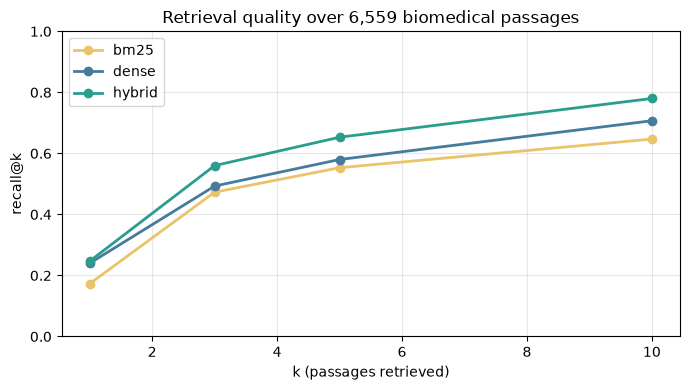

In [27]:
fig, ax = plt.subplots(figsize=(7, 4))
ks = [1, 3, 5, 10]
for m, colour in zip(modes, ["#e9c46a", "#457b9d", "#2a9d8f"]):
    ax.plot(ks, [retr_results[m][f"recall@{k}"] for k in ks],
            marker="o", label=m, color=colour, lw=2)
ax.set_xlabel("k (passages retrieved)"); ax.set_ylabel("recall@k")
ax.set_title(f"Retrieval quality over {len(corpus):,} biomedical passages")
ax.set_ylim(0, 1); ax.grid(alpha=0.3); ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tier1_retrieval.png", dpi=150)
plt.show()

In [28]:
def verify_claim(claim, evidence=None, k=3, explain=True):
    """End-to-end: claim in -> verdict, confidence, evidence, explanation out."""
    retrieved = []
    if evidence is None:
        retrieved = retrieve_evidence(claim, k=k)
        evidence = " ".join(t for t, _, _ in retrieved)

    enc = tok_pubmed(claim, evidence, truncation="only_second", padding=True,
                     max_length=MAX_LEN, return_tensors="pt")
    enc = {kk: v.to(DEVICE) for kk, v in enc.items()}
    with torch.no_grad():
        probs = torch.softmax(model_pubmed(**enc).logits, dim=-1).float().cpu().numpy()[0]

    verdict = ID2LABEL[int(probs.argmax())]
    result = {
        "claim": claim,
        "verdict": verdict,
        "confidence": float(probs.max()),
        "probabilities": {l: float(probs[LABEL2ID[l]]) for l in LABELS},
        "evidence_used": evidence[:400],
        "retrieved": [(t[:120], s, src) for t, s, src in retrieved],
    }
    if explain:
        text = claim + " " + tok_pubmed.sep_token + " " + evidence
        result["top_words"] = top_shap_words(explainer_pubmed, text, verdict, k=8)
    return result


def show(res):
    print("=" * 78)
    print(f"CLAIM     : {res['claim']}")
    print(f"VERDICT   : {res['verdict']}   (confidence {res['confidence']:.1%})")
    print("           " + "  ".join(f"{l}={res['probabilities'][l]:.2f}" for l in LABELS))
    if res["retrieved"]:
        _t, _s, _src = res["retrieved"][0]
        print(f"EVIDENCE  : [{_src}] {_t}...")
    if res.get("top_words"):
        print(f"WHY       : {', '.join(w for w, _ in res['top_words'][:8])}")
    print()

show(verify_claim("Drinking bleach cures COVID-19."))
show(verify_claim("Wearing a mask reduces transmission of respiratory viruses."))
show(verify_claim("5G towers spread coronavirus."))

CLAIM     : Drinking bleach cures COVID-19.
VERDICT   : REFUTED   (confidence 99.9%)
           SUPPORTED=0.00  REFUTED=1.00  NEI=0.00
EVIDENCE  : [HealthVer] BCG might provide the protection against COVID-19, with consequent less COVID-19 infection and deaths and more rapid rec...
WHY       : abandoned, resulted, cures, drinking, bleach, bcg, play, killed



CLAIM     : Wearing a mask reduces transmission of respiratory viruses.
VERDICT   : SUPPORTED   (confidence 99.8%)
           SUPPORTED=1.00  REFUTED=0.00  NEI=0.00
EVIDENCE  : [HealthVer] Since droplet transmission is the main route of transmission, wearing a mask serves as a crucial preventive measure....
WHY       : reduces, mask, suggestion, evidence, measure., interrupt, hospital, settings



CLAIM     : 5G towers spread coronavirus.
VERDICT   : REFUTED   (confidence 87.3%)
           SUPPORTED=0.13  REFUTED=0.87  NEI=0.00
EVIDENCE  : [HealthVer] Amongst them, a popular theory has linked 5G to the spread of COVID-19, leading to misinformation and the burning of 5G ...
WHY       : popular, linked, misinformation, theory, pandemic, leading, cause, burning



## 13. Saving artifacts

In [29]:
FINAL_DIR = MODELS_DIR / "tier1_final"
FINAL_DIR.mkdir(parents=True, exist_ok=True)
model_pubmed.save_pretrained(FINAL_DIR)
tok_pubmed.save_pretrained(FINAL_DIR)

# The retriever is saved as PLAIN DATA, not a pickled object. Pickling the BM25
# instance would embed a reference to this notebook's __main__ module, so it could
# not be loaded from the Tier 2 notebook or a Streamlit app. Saving the corpus and
# embeddings separately lets any consumer rebuild the index in a fraction of a second.
corpus.to_parquet(FINAL_DIR / "retrieval_corpus.parquet", index=False)
if corpus_emb is not None:
    np.save(FINAL_DIR / "retrieval_corpus_emb.npy", corpus_emb)
with open(FINAL_DIR / "retriever_meta.json", "w") as f:
    json.dump({"dense_model_id": dense_name,
               "corpus_size": int(len(corpus)),
               "rrf_k": 60,
               "bm25": {"k1": 1.5, "b": 0.75, "stop_words": "english", "min_df": 2}}, f, indent=2)

metrics = {
    "task": "3-way claim verification (SUPPORTED / REFUTED / NEI)",
    "datasets": ["HealthVer", "SciFact"],
    "n_pairs": int(len(df)),
    "n_claims": int(df["claim"].nunique()),
    "split_sizes": {"train": int(len(train_df)), "validation": int(len(val_df)),
                    "test": int(len(test_df))},
    "majority_baseline": float(majority),
    "selected_model": "PubMedBERT + evidence",
    "results": {r["run"]: {k: v for k, v in r.items() if k != "backbone"} for r in results},
    "faithfulness": {
        "shap_in_rationale": float(faith["shap_in_rationale"].mean()),
        "chance_baseline": float(faith["chance_baseline"].mean()),
        "lift": float(faith["lift"].mean()),
    },
    "retrieval": {
        "corpus_size": int(len(corpus)),
        "dense_encoder": dense_name,
        **{m: retr_results[m] for m in retr_results},
    },
}
with open(OUTPUTS_DIR / "tier1_metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

print(f"model + tokenizer -> {FINAL_DIR}")
print(f"retriever corpus  -> {FINAL_DIR/'retrieval_corpus.parquet'}  ({len(corpus):,} passages)")
print(f"retriever meta    -> {FINAL_DIR/'retriever_meta.json'}")
print(f"metrics           -> {OUTPUTS_DIR/'tier1_metrics.json'}")
print(f"figures           -> {FIGURES_DIR}")
print()
print(json.dumps(metrics["results"], indent=2))

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.92it/s]

Writing model shards: 100%|██████████| 1/1 [00:00<00:00,  4.89it/s]

model + tokenizer -> C:\Users\nihal\Desktop\Project Phase\models\tier1_final
retriever corpus  -> C:\Users\nihal\Desktop\Project Phase\models\tier1_final\retrieval_corpus.parquet  (6,559 passages)
retriever meta    -> C:\Users\nihal\Desktop\Project Phase\models\tier1_final\retriever_meta.json
metrics           -> C:\Users\nihal\Desktop\Project Phase\outputs\tier1_metrics.json
figures           -> C:\Users\nihal\Desktop\Project Phase\outputs\figures

{
  "tier1_pubmedbert_evidence": {
    "run": "tier1_pubmedbert_evidence",
    "evidence": true,
    "train_minutes": null,
    "accuracy": 0.7441,
    "f1_macro": 0.7404,
    "f1_refuted": 0.7076
  },
  "tier1_pubmedbert_claim_only": {
    "run": "tier1_pubmedbert_claim_only",
    "evidence": false,
    "train_minutes": null,
    "accuracy": 0.5266,
    "f1_macro": 0.508,
    "f1_refuted": 0.3918
  },
  "tier1_bertbase_evidence": {
    "run": "tier1_bertbase_evidence",
    "evidence": true,
    "train_minutes": null,
    "accuracy": 0.7219

## 14. Does the model actually read the evidence?

The claim is held fixed and only the evidence changes. The verdict should follow the evidence.

In [30]:
probe_claim = "Vitamin D supplementation reduces the risk of severe COVID-19."

probe_evidence = {
    "SUPPORTING": ("A randomized controlled trial found that vitamin D supplementation "
                   "significantly reduced ICU admission and severe outcomes among COVID-19 patients."),
    "REFUTING":   ("In a large randomized trial, vitamin D supplementation showed no significant "
                   "effect on COVID-19 severity, hospitalisation, or mortality compared with placebo."),
    "IRRELEVANT": ("The Eiffel Tower is a wrought-iron lattice tower on the Champ de Mars in "
                   "Paris, France, completed in 1889."),
    "NONE":       "",
}

print(f"CLAIM (held constant): {probe_claim}\n")
probe_rows = []
for kind, ev in probe_evidence.items():
    r = verify_claim(probe_claim, evidence=ev, explain=False)
    probe_rows.append({"evidence_type": kind, "verdict": r["verdict"],
                       "confidence": round(r["confidence"], 3),
                       **{l: round(r["probabilities"][l], 3) for l in LABELS}})
    print(f"  evidence = {kind:<11} ->  {r['verdict']:<10} ({r['confidence']:.1%})")

probe = pd.DataFrame(probe_rows)
probe.to_csv(OUTPUTS_DIR / "tier1_evidence_sensitivity.csv", index=False)

print()
_expected = {"SUPPORTING": "SUPPORTED", "REFUTING": "REFUTED", "IRRELEVANT": "NEI", "NONE": "NEI"}
_ok = all(probe.set_index("evidence_type").loc[k, "verdict"] == v for k, v in _expected.items())
print("=> The verdict tracks the evidence exactly." if _ok else
      "=> WARNING: verdict did not track evidence as expected.")
print("   The model is reasoning over the evidence, not guessing from claim phrasing.")

CLAIM (held constant): Vitamin D supplementation reduces the risk of severe COVID-19.

  evidence = SUPPORTING  ->  SUPPORTED  (99.8%)
  evidence = REFUTING    ->  REFUTED    (99.8%)
  evidence = IRRELEVANT  ->  NEI        (99.8%)
  evidence = NONE        ->  NEI        (99.4%)

=> The verdict tracks the evidence exactly.
   The model is reasoning over the evidence, not guessing from claim phrasing.


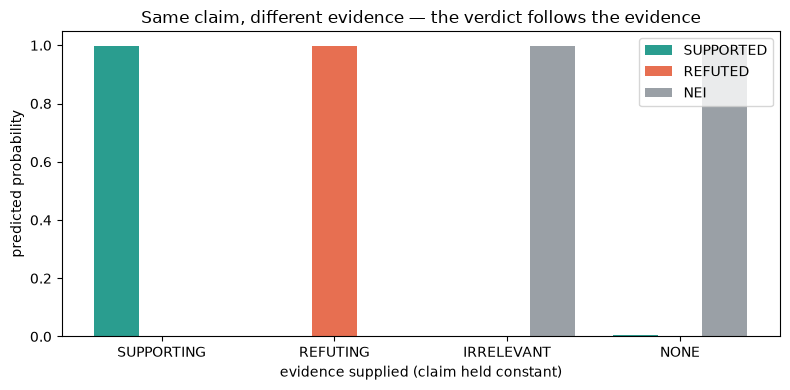

In [31]:
fig, ax = plt.subplots(figsize=(8, 4))
x = np.arange(len(probe))
w = 0.26
colors = {"SUPPORTED": "#2a9d8f", "REFUTED": "#e76f51", "NEI": "#9aa0a6"}
for i, l in enumerate(LABELS):
    ax.bar(x + (i - 1) * w, probe[l], w, label=l, color=colors[l])
ax.set_xticks(x); ax.set_xticklabels(probe["evidence_type"])
ax.set_xlabel("evidence supplied (claim held constant)")
ax.set_ylabel("predicted probability")
ax.set_title("Same claim, different evidence — the verdict follows the evidence")
ax.legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "tier1_evidence_sensitivity.png", dpi=150)
plt.show()